In [6]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [16]:
# define state
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [11]:
def calculate_bmi(state: BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']

    bmi = weight / (height**2)

    state['bmi'] = round(bmi, 2)
    
    return state

In [17]:
def lebel_emi(state: BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"
    return state

In [18]:
#define graph
graph = StateGraph(BMIState)

#add nodes to graph
graph.add_node('calculate_bmi', calculate_bmi)
graph.add_node('lebel_emi', lebel_emi)

#add edges
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'lebel_emi')
graph.add_edge('lebel_emi', END)

#compile
workflow = graph.compile()

In [19]:
#execute
initial_state = {'weight_kg' : 80, 'height_m' : 1.5}

output_state = workflow.invoke(initial_state)
output_state

{'weight_kg': 80, 'height_m': 1.5, 'bmi': 35.56, 'category': 'Obese'}

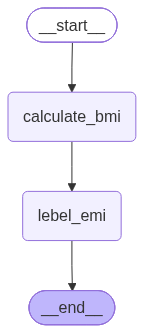

In [20]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())